In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".99"




In [2]:
import torch
from transformers import AutoTokenizer
from transformers import AutoModelForCausalLM

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

Target Device: cuda


In [3]:
import jax
import jax.numpy as jnp
from qwen_fineTuning_PtoC import QwenTextClassificationWrapper
import numpy as np
from flax.core import freeze, unfreeze

%load_ext autoreload
%autoreload 2

# with np.load("datasets/text_classification/boolq/train_data.npz") as data:
with np.load("datasets/text_classification/winogrande_s/test_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])
    all_target_ids = jnp.array(data['target_ids'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape, all_target_ids.shape

((1264, 64), (1264, 64), (1264,), (1264,), (2, 1))

In [4]:

model = QwenTextClassificationWrapper("datasets/model_exports/qwen2.5_3B_float16", target_token_ids=all_target_ids)

params = model.init(None, None)
params = unfreeze(params)
params

{'params': {'embed_tokens': {'embedding': Array([[ 3.9551e-02,  1.4099e-02, -1.5442e-02, ..., -3.3447e-02,
            1.5320e-02,  2.6611e-02],
          [ 1.0925e-02,  1.4160e-02, -1.2207e-02, ..., -6.1340e-03,
           -1.3367e-02,  4.3213e-02],
          [-2.7222e-02, -2.5146e-02,  1.7334e-02, ..., -2.8442e-02,
            3.1586e-03,  2.4536e-02],
          ...,
          [-1.0559e-02, -1.5831e-04, -2.5177e-03, ...,  4.4250e-03,
           -7.1526e-05, -2.7618e-03],
          [-1.0559e-02, -1.5831e-04, -2.5177e-03, ...,  4.4250e-03,
           -7.1526e-05, -2.7618e-03],
          [-1.0559e-02, -1.5831e-04, -2.5177e-03, ...,  4.4250e-03,
           -7.1526e-05, -2.7618e-03]], dtype=float16)},
  'layers_0': {'input_layernorm': {'weight': Array([0.2676, 0.3398, 0.2852, ..., 0.2695, 0.5156, 0.3652], dtype=float16)},
   'mlp': {'down_proj': {'kernel': Array([[-0.02075 ,  0.0459  ,  0.04565 , ...,  0.00406 ,  0.0293  ,
             -0.007294],
            [ 0.03247 , -0.004395, -0.017

In [5]:
# with lora
from src.subspace_curve import CategorySubspace, filter_mask, LoRACategorySubspace

lora_mask = jax.tree.map(lambda x: False, params)['params']
lora_mask = filter_mask(lora_mask, "self_attn", "q_proj", "kernel", as_curve=np.array([1,0]))
lora_mask = filter_mask(lora_mask, "self_attn", "v_proj", "kernel", as_curve=np.array([1,0]))

key = jax.random.PRNGKey(0)
s_model = LoRACategorySubspace(model=model, k=2, lora_mask=lora_mask, r=8, lora_dtype='float32', lora_alpha=16.)

curve_mask = jax.tree.map(lambda x: False, params)['params']
curve_mask = filter_mask(curve_mask, "self_attn", "q_proj", "kernel", as_curve=True)
curve_mask = filter_mask(curve_mask, "self_attn", "v_proj", "kernel", as_curve=True)

train_mask = jax.tree.map(lambda x: False, params['params'])
train_mask = filter_mask(train_mask, "self_attn", "q_proj", "kernel", as_curve=True)
train_mask = filter_mask(train_mask, "self_attn", "v_proj", "kernel", as_curve=True)

s_params = s_model.init_params_from_point(key, params, curve_mask, noise_fn=lambda p, key: p)
del params

train_mask = s_model.update_mask_for_lora(train_mask, s_params['params'], b_off=False, w0_off=True) # w0 must be off for LoRA
s_model.set_train_mask(train_mask)
s_model(s_params['params'], {}, 0.5, (input_ids[:12], attention_mask[:12]), train=False)

(Array([[8.0234375, 5.1484375],
        [7.9453125, 4.9960938],
        [8.4296875, 7.3710938],
        [8.3359375, 6.3710938],
        [7.4921875, 7.6015625],
        [7.8984375, 8.4375   ],
        [7.3710938, 8.3125   ],
        [7.4570312, 8.953125 ],
        [5.6835938, 9.1484375],
        [8.21875  , 7.5976562],
        [8.1015625, 6.7929688],
        [6.9375   , 9.2734375]], dtype=float32),
 {})

In [6]:
s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape

{'A': (3, 8, 2048), 'B': (2048, 8), 'w0': (2048, 2048)}

In [7]:
print(s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].A.dtype)
print(s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].B.dtype)
print(s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].w0.dtype)

float32
float32
float16


In [8]:
# from qwen_fineTuning_PtoC import setup_metrics

# metrics = setup_metrics(s_model, 4, input_ids[:12], attention_mask[:12], labels[:12], 1, use_linspace=True, average=True)
# metrics(key, s_params)

#### optimize curve

In [9]:
s_model.train_mask

{'embed_tokens': {'embedding': False},
 'layers_0': {'input_layernorm': {'weight': False},
  'mlp': {'down_proj': {'kernel': False},
   'gate_proj': {'kernel': False},
   'up_proj': {'kernel': False}},
  'post_attention_layernorm': {'weight': False},
  'self_attn': {'k_proj': {'bias': False, 'kernel': False},
   'o_proj': {'kernel': False},
   'q_proj': {'bias': False,
    'kernel': LoRAParams(A=True, B=True, w0=False) with dims=(1, 0) and lora_alpha=16.0)},
   'v_proj': {'bias': False,
    'kernel': LoRAParams(A=True, B=True, w0=False) with dims=(1, 0) and lora_alpha=16.0)}}},
 'layers_1': {'input_layernorm': {'weight': False},
  'mlp': {'down_proj': {'kernel': False},
   'gate_proj': {'kernel': False},
   'up_proj': {'kernel': False}},
  'post_attention_layernorm': {'weight': False},
  'self_attn': {'k_proj': {'bias': False, 'kernel': False},
   'o_proj': {'kernel': False},
   'q_proj': {'bias': False,
    'kernel': LoRAParams(A=True, B=True, w0=False) with dims=(1, 0) and lora_alpha

In [10]:
from optax import adamw


optimizer = adamw(1e-3)
trainable_params = s_model.only_trainable_params(s_params['params'])
opt_state = optimizer.init(trainable_params)

In [11]:
sub_key = jax.random.PRNGKey(1)
loss, s_params, opt_state, grad_ = s_model.train_step(
                    sub_key, s_params, (input_ids[:4], attention_mask[:4]), labels[:4], opt_state, optimizer)

loss, s_params, opt_state, grad_ = s_model.train_step(
                    sub_key, s_params, (input_ids[4:8], attention_mask[4:8]), labels[4:8], opt_state, optimizer)

loss, s_params, opt_state, grad_ = s_model.train_step(
                    sub_key, s_params, (input_ids[8:12], attention_mask[8:12]), labels[8:12], opt_state, optimizer)
loss

Array(0.57725286, dtype=float32)

#### define line sampling model

Control points shape: (3, 344064)
Control points in phi space: (3, 2)
Logits: Traced<ShapedArray(float32[4,2])>with<DynamicJaxprTrace>
Logits: Traced<ShapedArray(float32[4,2])>with<DynamicJaxprTrace>


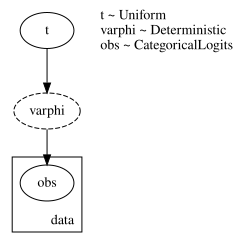

In [ ]:
# memory inefficient version

import numpyro
import numpyro.distributions as dist
from numpyro import handlers
import arviz as az
from src.subspace_curve import masked_pytree_to_matrix, OrthoSpan, bezier_curve, LoRAParams


def init_sampling_model(model, params):
    # get design matrix from curve parameters stored as pytree
    cp_w = masked_pytree_to_matrix(params['params'], model.curve_mask, model.k)
    print(f"Control points shape: {cp_w.shape}")

    # define the transformation function between weight space and phi space
    t_phi_to_weight = OrthoSpan(cp_w)

    # control points in the varphi space
    cp_phi = t_phi_to_weight.inv(cp_w)
    print(f"Control points in phi space: {cp_phi.shape}")

    # define t_lambda to phi mapping using bezier curve (get point in varphi space from lambda (t))
    def init_t_lambda_to_phi(cp_phi, k,):
        curve, d_bezier = bezier_curve(k+1, cp_phi)
        def clousure(t):
            space_point = curve(t)
            return space_point
        return jax.jit(clousure), curve, d_bezier

    t_lambda_to_phi, _, _ = init_t_lambda_to_phi(cp_phi, s_model.k)

    def create_vec_to_pytree_fn(template_params, curve_mask):
        """Factory function - compute indices once, reuse many times"""
        
        # Pre-compute all slice indices
        leaf_shapes = jax.tree.map(
            lambda p, m: p.shape[1:] if m else (0,),
            template_params, curve_mask
        )
        flat_shapes, structure = jax.tree.flatten(leaf_shapes, is_leaf=lambda x: isinstance(x, tuple))
        
        # Compute cumulative indices (static!)
        sizes = [np.prod(s) for s in flat_shapes]
        indices = np.cumsum([0] + sizes)
        
        @jax.jit
        def vec_to_pytree(vec):
            """Fast conversion with pre-computed indices"""
            
            new_leaves = [jnp.reshape(vec[indices[i]:indices[i+1]], s) for i, s in enumerate(flat_shapes)]
            curve_point = jax.tree.unflatten(structure, new_leaves)

            # map curve point with non curve params
            curve_point = jax.tree.map(lambda m, cp, p: cp if m else p, curve_mask, curve_point, template_params)
            # apply LoRAParams to get full weight
            curve_point = jax.tree.map(lambda lp: lp.apply() if isinstance(lp, LoRAParams) else lp, curve_point, is_leaf=lambda x: isinstance(x, LoRAParams))
            return curve_point
        
        return vec_to_pytree
    
    vec_to_pytree = create_vec_to_pytree_fn(params['params'], model.curve_mask)

    mutable_state = params[model.mutable_name] if model.mutable_name else {}

    def model_line(x, y=None, temperature=1.):
        # t = numpyro.sample("t", dist.Uniform(-0.3, 1.3).expand((1,)).to_event(1))
        t = numpyro.sample("t", dist.Uniform(-0.3, 1.3))
        varphi = t_lambda_to_phi(t)

        # jacobian = jax.jacrev(transform)(jax.lax.stop_gradient(lambda_)).squeeze()
        # jacobian = jax.jacrev(t_lambda_to_phi)(t)
        # # sign, logabsdet = jnp.linalg.slogdet(jacobian)
        # norm = jnp.linalg.norm(jacobian)
        # numpyro.factor("norm", norm)

        varphi = numpyro.deterministic('varphi', varphi)
        weight_vec = t_phi_to_weight(varphi)
        weight_pytree = vec_to_pytree(weight_vec)

        def apply_model(weight_pytree, x, mutable_state):
            out, _ = model._predict(weight_pytree, mutable_state, x, train=False)
            return out

        if weight_vec.ndim == 1:
            out = apply_model(weight_pytree, x, mutable_state)
        else:
            out = jax.vmap(apply_model, in_axes=(0, None, None))(weight_pytree, x, mutable_state)

        with numpyro.plate("data", x[0].shape[0], dim=-1):
            with handlers.scale(scale=1/temperature):
                print("Logits:", out)
                numpyro.sample("obs", dist.Categorical(logits=out), obs=y)
        return out
    return model_line

model_line = init_sampling_model(s_model, s_params)

x = (input_ids[:4], attention_mask[:4])
y = labels[:4]
# Example usage:
numpyro.render_model(model_line, model_args=(
    x,), render_distributions=True, )

Control points shape: (3, 344064)
Control points in phi space: (3, 2)
Logits: Traced<ShapedArray(float32[4,2])>with<DynamicJaxprTrace>
Logits: Traced<ShapedArray(float32[4,2])>with<DynamicJaxprTrace>


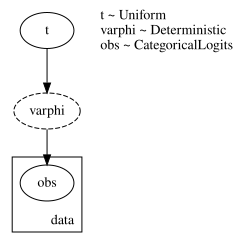

In [ ]:
# memory inefficient version

import numpyro
import numpyro.distributions as dist
from numpyro import handlers
import arviz as az
from functools import partial
from src.subspace_curve import masked_pytree_to_matrix, OrthoSpan, bezier_curve, LoRAParams


def init_sampling_model(model, params):
    # get design matrix from curve parameters stored as pytree
    cp_w = masked_pytree_to_matrix(params['params'], model.curve_mask, model.k)
    print(f"Control points shape: {cp_w.shape}")

    # define the transformation function between weight space and phi space
    t_phi_to_weight = OrthoSpan(cp_w)

    # control points in the varphi space
    cp_phi = t_phi_to_weight.inv(cp_w)
    print(f"Control points in phi space: {cp_phi.shape}")

    # define t_lambda to phi mapping using bezier curve (get point in varphi space from lambda (t))
    def init_t_lambda_to_phi(cp_phi, k,):
        curve, d_bezier = bezier_curve(k+1, cp_phi)
        def clousure(t):
            space_point = curve(t)
            return space_point
        return jax.jit(clousure), curve, d_bezier

    t_lambda_to_phi, _, _ = init_t_lambda_to_phi(cp_phi, s_model.k)

    def create_vec_to_pytree_fn(template_params, curve_mask):
        """Factory function - compute indices once, reuse many times"""
        
        # Pre-compute all slice indices
        leaf_shapes = jax.tree.map(
            lambda p, m: p.shape[1:] if m else (0,),
            template_params, curve_mask
        )
        flat_shapes, structure = jax.tree.flatten(leaf_shapes, is_leaf=lambda x: isinstance(x, tuple))
        
        # Compute cumulative indices (static!)
        sizes = [np.prod(s) for s in flat_shapes]
        indices = np.cumsum([0] + sizes)

        # @partial(jax.jit, donate_argnums=1)
        @partial(jax.jit)
        def vec_to_pytree(vec, params):
            """Fast conversion with pre-computed indices"""
            
            new_leaves = [jnp.reshape(vec[indices[i]:indices[i+1]], s) for i, s in enumerate(flat_shapes)]
            curve_point = jax.tree.unflatten(structure, new_leaves)

            # map curve point with non curve params
            params = jax.tree.map(lambda m, cp, p: cp if m else p, curve_mask, curve_point, params)
            # apply LoRAParams to get full weight
            params = jax.tree.map(lambda lp: lp.apply() if isinstance(lp, LoRAParams) else lp, params, is_leaf=lambda x: isinstance(x, LoRAParams))
            return params
        
        return vec_to_pytree
    
    vec_to_pytree = create_vec_to_pytree_fn(params['params'], model.curve_mask)

    mutable_state = params[model.mutable_name] if model.mutable_name else {}

    def model_line(x, y=None, temperature=1.):
        # t = numpyro.sample("t", dist.Uniform(-0.3, 1.3).expand((1,)).to_event(1))
        t = numpyro.sample("t", dist.Uniform(-0.3, 1.3))
        varphi = t_lambda_to_phi(t)

        # jacobian = jax.jacrev(transform)(jax.lax.stop_gradient(lambda_)).squeeze()
        # jacobian = jax.jacrev(t_lambda_to_phi)(t)
        # # sign, logabsdet = jnp.linalg.slogdet(jacobian)
        # norm = jnp.linalg.norm(jacobian)
        # numpyro.factor("norm", norm)

        varphi = numpyro.deterministic('varphi', varphi)
        weight_vec = t_phi_to_weight(varphi)
        weight_pytree = vec_to_pytree(weight_vec, params['params'])

        def apply_model(weight_pytree, x, mutable_state):
            out, _ = model._predict(weight_pytree, mutable_state, x, train=False)
            return out

        if weight_vec.ndim == 1:
            out = apply_model(weight_pytree, x, mutable_state)
        else:
            out = jax.vmap(apply_model, in_axes=(0, None, None))(weight_pytree, x, mutable_state)

        with numpyro.plate("data", x[0].shape[0], dim=-1):
            with handlers.scale(scale=1/temperature):
                print("Logits:", out)
                numpyro.sample("obs", dist.Categorical(logits=out), obs=y)
        return out
    return model_line

model_line = init_sampling_model(s_model, s_params)

x = (input_ids[:4], attention_mask[:4])
y = labels[:4]
# Example usage:
numpyro.render_model(model_line, model_args=(
    x,), render_distributions=True, )

In [9]:
# memory efficient version
 
import numpyro
import numpyro.distributions as dist
from numpyro import handlers
import arviz as az
from functools import partial
from src.subspace_curve import masked_pytree_to_matrix, OrthoSpan, bezier_curve, LoRAParams
import gc


def init_sampling_model(model, params):
    # get design matrix from curve parameters stored as pytree
    cp_w = masked_pytree_to_matrix(params['params'], model.curve_mask, model.k)
    print(f"Control points shape: {cp_w.shape}")

    # define the transformation function between weight space and phi space
    t_phi_to_weight = OrthoSpan(cp_w)

    # control points in the varphi space
    cp_phi = t_phi_to_weight.inv(cp_w)
    print(f"Control points in phi space: {cp_phi.shape}")

    # define t_lambda to phi mapping using bezier curve (get point in varphi space from lambda (t))
    def init_t_lambda_to_phi(cp_phi, k,):
        curve, d_bezier = bezier_curve(k+1, cp_phi)
        def clousure(t):
            space_point = curve(t)
            return space_point
        return jax.jit(clousure), curve, d_bezier

    t_lambda_to_phi, _, _ = init_t_lambda_to_phi(cp_phi, s_model.k)

    def create_vec_to_pytree_fn(template_params, curve_mask):
        """Factory function - compute indices once, reuse many times"""
        
        # Pre-compute all slice indices
        leaf_shapes = jax.tree.map(
            lambda p, m: p.shape[1:] if m else (0,),
            template_params, curve_mask
        )
        flat_shapes, structure = jax.tree.flatten(leaf_shapes, is_leaf=lambda x: isinstance(x, tuple))
        
        # Compute cumulative indices (static!)
        sizes = [np.prod(s) for s in flat_shapes]
        indices = np.cumsum([0] + sizes)

        # @partial(jax.jit, donate_argnums=1)
        @partial(jax.jit)
        def vec_to_pytree(vec):
            """Fast conversion with pre-computed indices"""
            
            new_leaves = [jnp.reshape(vec[indices[i]:indices[i+1]], s) for i, s in enumerate(flat_shapes)]
            curve_point = jax.tree.unflatten(structure, new_leaves)
            return curve_point

            # # map curve point with non curve params
            # params = jax.tree.map(lambda m, cp, p: cp if m else p, curve_mask, curve_point, params)
            # # apply LoRAParams to get full weight
            # params = jax.tree.map(lambda lp: lp.apply() if isinstance(lp, LoRAParams) else lp, params, is_leaf=lambda x: isinstance(x, LoRAParams))
            # return params
        
        return vec_to_pytree
    
    vec_to_pytree = create_vec_to_pytree_fn(params['params'], model.curve_mask)

    mutable_state = params[model.mutable_name] if model.mutable_name else {}

    def model_line(x, params, y=None, temperature=1.):
        # t = numpyro.sample("t", dist.Uniform(-0.3, 1.3).expand((1,)).to_event(1))
        t = numpyro.sample("t", dist.Uniform(-0.3, 1.3))
        varphi = t_lambda_to_phi(t)

        # jacobian = jax.jacrev(transform)(jax.lax.stop_gradient(lambda_)).squeeze()
        # jacobian = jax.jacrev(t_lambda_to_phi)(t)
        # # sign, logabsdet = jnp.linalg.slogdet(jacobian)
        # norm = jnp.linalg.norm(jacobian)
        # numpyro.factor("norm", norm)

        varphi = numpyro.deterministic('varphi', varphi)
        weight_vec = t_phi_to_weight(varphi)
        weight_pytree = vec_to_pytree(weight_vec)
        params = jax.tree.map(lambda m, cp, p: cp if m else p, model.curve_mask, weight_pytree, params)
        # apply LoRAParams to get full weight
        params = jax.tree.map(lambda lp: lp.apply() if isinstance(lp, LoRAParams) else lp, params, is_leaf=lambda x: isinstance(x, LoRAParams))

        def apply_model(weight_pytree, x, mutable_state):
            out, _ = model._predict(weight_pytree, mutable_state, x, train=False)
            return out

        with numpyro.plate("data", x[0].shape[0], subsample_size=16) as idx:
            x_subset = (x[0][idx], x[1][idx])
            if weight_vec.ndim == 1:
                out = apply_model(params, x_subset, mutable_state)
            else:
                out = jax.vmap(apply_model, in_axes=(0, None, None))(params, x_subset, mutable_state)

            with handlers.scale(scale=1/temperature):
                print("Logits:", out)
                numpyro.sample("obs", dist.Categorical(logits=out), obs=y[idx])
        return out
    return model_line

model_line = init_sampling_model(s_model, s_params)

# del curve params
s_params['params'] = jax.tree.map(lambda m, p: None if m else p, s_model.curve_mask, s_params['params'])
gc.collect()

x = (input_ids[:32], attention_mask[:32])
y = labels[:32]
# Example usage:
numpyro.render_model(model_line, model_args=(
    x, s_params['params']), render_distributions=True, )

Control points shape: (3, 1179648)
Control points in phi space: (3, 2)
Logits: Traced<ShapedArray(float32[16,2])>with<DynamicJaxprTrace>


TypeError: 'NoneType' object is not subscriptable

In [12]:

from numpyro.infer.util import initialize_model

init_params, potential_fn, *_ = initialize_model(key, model_line, model_args=(x, s_params['params'], y), model_kwargs={'temperature': 1.0}, dynamic_args=False)
logdensity_fn = lambda t: -potential_fn(t)
logdensity_fn({'t':.5})

Logits: [[6.53125 8.375  ]
 [6.53125 8.375  ]
 [5.78125 9.5625 ]
 [6.46875 9.875  ]]
Logits: Traced<ShapedArray(float32[4,2])>with<JVPTrace> with
  primal = Array([[6.5    , 8.375  ],
       [6.59375, 8.4375 ],
       [5.71875, 9.5    ],
       [6.46875, 9.8125 ]], dtype=float32)
  tangent = Traced<ShapedArray(float32[4,2])>with<JaxprTrace> with
    pval = (ShapedArray(float32[4,2]), None)
    recipe = JaxprEqnRecipe(eqn_id=<object object at 0x7b8d436bdb50>, in_tracers=(Traced<ShapedArray(bfloat16[896,896]):JaxprTrace>, Traced<ShapedArray(bfloat16[896,128]):JaxprTrace>, Traced<ShapedArray(bfloat16[896,896]):JaxprTrace>, Traced<ShapedArray(bfloat16[896,128]):JaxprTrace>, Traced<ShapedArray(bfloat16[896,896]):JaxprTrace>, Traced<ShapedArray(bfloat16[896,128]):JaxprTrace>, Traced<ShapedArray(bfloat16[896,896]):JaxprTrace>, Traced<ShapedArray(bfloat16[896,128]):JaxprTrace>, Traced<ShapedArray(bfloat16[896,896]):JaxprTrace>, Traced<ShapedArray(bfloat16[896,128]):JaxprTrace>, Traced<ShapedAr

Array(-7.047093, dtype=float32)

In [20]:
logdensity_fn({'t':.5})

Logits: [[ 6.53125  8.375  ]
 [ 6.53125  8.375  ]
 [ 5.78125  9.5625 ]
 [ 6.46875  9.875  ]
 [ 6.625    9.3125 ]
 [ 6.15625  9.3125 ]
 [ 7.375   10.875  ]
 [ 7.375   10.4375 ]
 [ 6.53125  8.6875 ]
 [ 6.09375 10.375  ]
 [ 6.03125 10.25   ]
 [ 7.3125   9.5625 ]]


Array(-21.093172, dtype=float32)

In [21]:
logdensity_fn({'t':0.1})

Logits: [[ 6.53125  8.375  ]
 [ 6.53125  8.375  ]
 [ 5.78125  9.5625 ]
 [ 6.46875  9.875  ]
 [ 6.625    9.3125 ]
 [ 6.15625  9.3125 ]
 [ 7.375   10.875  ]
 [ 7.375   10.4375 ]
 [ 6.53125  8.6875 ]
 [ 6.09375 10.375  ]
 [ 6.03125 10.25   ]
 [ 7.3125   9.5625 ]]


Array(-21.033812, dtype=float32)

In [10]:
x = (input_ids[:32], attention_mask[:32])
y = labels[:32]

cml = handlers.substitute(model_line, data={'t': jnp.array(0.1)})
ex_trace = handlers.trace(handlers.seed(cml, jax.random.PRNGKey(2))).get_trace(x, s_params['params'], y, 1.)
site = ex_trace['obs']
log_like = (site['fn'].log_prob(site['value']) * site['scale']).sum(-1)
print("Log likelihood:", log_like)
# site = ex_trace['logabsdet']
# logabsdet = site['fn'].log_prob(site['value'])
site = ex_trace['t']
prior = site['fn'].log_prob(site['value'])
print("Prior log prob:", prior)
logdensity = log_like + prior
print("Total log density:", logdensity)

Logits: [[7.2070312 8.9921875]
 [6.5507812 8.6796875]
 [8.1796875 7.640625 ]
 [7.75      7.171875 ]
 [6.9570312 9.296875 ]
 [7.515625  7.5742188]
 [8.703125  5.6640625]
 [6.109375  9.546875 ]
 [6.5507812 8.8046875]
 [7.21875   5.2109375]
 [7.8359375 5.6640625]
 [7.5117188 8.984375 ]
 [8.125     6.8515625]
 [8.265625  7.6679688]
 [7.3867188 8.328125 ]
 [7.9414062 8.4375   ]]
Log likelihood: -21.644669
Prior log prob: -0.47000366
Total log density: -22.114672


In [35]:
ex_trace['data']['fn']

<function numpyro.primitives._subsample_fn(size, subsample_size, rng_key=None)>

### classic

In [12]:
import numpyro.distributions as dist
from functools import partial
from src.subspace_curve import masked_pytree_to_matrix, OrthoSpan, bezier_curve, LoRAParams
import gc
from einshape import jax_einshape as es


def init_sampling_model(model, params, batch_size=16):
    # get design matrix from curve parameters stored as pytree
    cp_w = masked_pytree_to_matrix(params['params'], model.curve_mask, model.k)
    print(f"Control points shape: {cp_w.shape}")

    # define the transformation function between weight space and phi space
    t_phi_to_weight = OrthoSpan(cp_w)

    # control points in the varphi space
    cp_phi = t_phi_to_weight.inv(cp_w)
    print(f"Control points in phi space: {cp_phi.shape}")

    # define t_lambda to phi mapping using bezier curve (get point in varphi space from lambda (t))
    def init_t_lambda_to_phi(cp_phi, k,):
        curve, d_bezier = bezier_curve(k+1, cp_phi)
        def clousure(t):
            space_point = curve(t)
            return space_point
        return jax.jit(clousure), curve, d_bezier

    t_lambda_to_phi, _, _ = init_t_lambda_to_phi(cp_phi, s_model.k)

    def create_vec_to_pytree_fn(template_params, curve_mask):
        """Factory function - compute indices once, reuse many times"""
        
        # Pre-compute all slice indices
        leaf_shapes = jax.tree.map(
            lambda p, m: p.shape[1:] if m else (0,),
            template_params, curve_mask
        )
        flat_shapes, structure = jax.tree.flatten(leaf_shapes, is_leaf=lambda x: isinstance(x, tuple))
        
        # Compute cumulative indices (static!)
        sizes = [np.prod(s) for s in flat_shapes]
        indices = np.cumsum([0] + sizes)

        # @partial(jax.jit, donate_argnums=1)
        @partial(jax.jit)
        def vec_to_pytree(vec):
            """Fast conversion with pre-computed indices"""
            
            new_leaves = [jnp.reshape(vec[indices[i]:indices[i+1]], s) for i, s in enumerate(flat_shapes)]
            curve_point = jax.tree.unflatten(structure, new_leaves)
            return curve_point

            # # map curve point with non curve params
            # params = jax.tree.map(lambda m, cp, p: cp if m else p, curve_mask, curve_point, params)
            # # apply LoRAParams to get full weight
            # params = jax.tree.map(lambda lp: lp.apply() if isinstance(lp, LoRAParams) else lp, params, is_leaf=lambda x: isinstance(x, LoRAParams))
            # return params
        
        return vec_to_pytree
    
    vec_to_pytree = create_vec_to_pytree_fn(params['params'], model.curve_mask)

    mutable_state = params[model.mutable_name] if model.mutable_name else {}

    @partial(jax.jit)
    def model_line(t, params, x, attm, y):
        # t = numpyro.sample("t", dist.Uniform(-0.3, 1.3).expand((1,)).to_event(1))
        # t = numpyro.sample("t", dist.Uniform(-0.3, 1.3))
        prior = dist.Uniform(-0.3, 1.3).log_prob(t)
        varphi = t_lambda_to_phi(t)

        # jacobian = jax.jacrev(transform)(jax.lax.stop_gradient(lambda_)).squeeze()
        # jacobian = jax.jacrev(t_lambda_to_phi)(t)
        # # sign, logabsdet = jnp.linalg.slogdet(jacobian)
        # norm = jnp.linalg.norm(jacobian)
        # numpyro.factor("norm", norm)

        # varphi = numpyro.deterministic('varphi', varphi)
        weight_vec = t_phi_to_weight(varphi)
        weight_pytree = vec_to_pytree(weight_vec)
        params = jax.tree.map(lambda m, cp, p: cp if m else p, model.curve_mask, weight_pytree, params)
        # apply LoRAParams to get full weight
        params = jax.tree.map(lambda lp: lp.apply() if isinstance(lp, LoRAParams) else lp, params, is_leaf=lambda x: isinstance(x, LoRAParams))

        def ll_batch(state, data):
            x, attm, y = data
            params, mutable_state = state
            logits, _ = model._predict(params, mutable_state, (x, attm), train=False)
            ll = dist.Categorical(logits=logits).log_prob(y).sum()
            return state, (ll, logits)

        # prepare batch data
        x_ = x[:(matching_limit:=(x.shape[0] // batch_size) * batch_size)]  # drop non matching batch size
        x_last = x[matching_limit:]
        x_ = es('(ib)...->ib...', x_, b=batch_size)

        att_m_ = attention_mask[:matching_limit]  # drop non matching batch size
        att_last = attention_mask[matching_limit:]
        att_m_ = es('(ib)...->ib...', att_m_, b=batch_size)

        y_ = y[:matching_limit]  # drop non matching batch size
        y_last = y[matching_limit:]
        y_ = es('(ib)...->ib...', y_, b=batch_size)

        _, (ll, logits) = jax.lax.scan(ll_batch, (params, mutable_state), (x_, att_m_, y_))
        logits = logits.reshape(-1, logits.shape[-1])
        ll = jnp.sum(ll)
        # last batch
        if x_last.shape[0] > 0:
            logits_, _ = model._predict(params, mutable_state, (x_last, att_last), train=False)
            logits = jnp.concatenate([logits, logits_], axis=0)
            ll += dist.Categorical(logits=logits_).log_prob(y_last).sum()

        return ll, prior, logits, varphi
    return model_line

model_line = init_sampling_model(s_model, s_params, batch_size=16)

# del curve params
s_params['params'] = jax.tree.map(lambda m, p: None if m else p, s_model.curve_mask, s_params['params'])
gc.collect()


Control points shape: (3, 1179648)
Control points in phi space: (3, 2)


0

In [13]:
gc.collect()

0

In [14]:
jax.tree.map(lambda s: f"{s/1024**2}MB", jax.devices()[0].memory_stats())

{'bytes_in_use': '6041.013671875MB',
 'bytes_limit': '15788.148901939392MB',
 'bytes_reserved': '0.0MB',
 'largest_alloc_size': '1103.689208984375MB',
 'largest_free_block_bytes': '0.0MB',
 'num_allocs': '0.009570121765136719MB',
 'peak_bytes_in_use': '7151.753662109375MB',
 'peak_bytes_reserved': '0.0MB',
 'peak_pool_bytes': '8194.0MB',
 'pool_bytes': '8194.0MB'}

In [15]:
# x = (input_ids, attention_mask)
# y = labels
ll, prior, logits, varphi = model_line(0.1, s_params['params'], input_ids, attention_mask, labels)
ll, prior, logits, varphi

(Array(-909.6117, dtype=float32),
 Array(-0.47000363, dtype=float32, weak_type=True),
 Array([[7.9570312, 5.9023438],
        [7.8710938, 5.4023438],
        [8.3046875, 7.921875 ],
        ...,
        [8.0546875, 7.5820312],
        [8.859375 , 5.6953125],
        [7.6757812, 8.8359375]], dtype=float32),
 Array([-0.15992652, -0.57223237], dtype=float32))

In [16]:

ll, prior, logits, varphi = model_line(0.1, s_params['params'], input_ids, attention_mask, labels)
ll, prior, logits, varphi

(Array(-909.6117, dtype=float32),
 Array(-0.47000363, dtype=float32, weak_type=True),
 Array([[7.9570312, 5.9023438],
        [7.8710938, 5.4023438],
        [8.3046875, 7.921875 ],
        ...,
        [8.0546875, 7.5820312],
        [8.859375 , 5.6953125],
        [7.6757812, 8.8359375]], dtype=float32),
 Array([-0.15992652, -0.57223237], dtype=float32))

In [17]:

ll, prior, logits, varphi = model_line(0.2, s_params['params'], input_ids, attention_mask, labels)
ll, prior, logits, varphi

(Array(-905.73804, dtype=float32),
 Array(-0.47000363, dtype=float32, weak_type=True),
 Array([[7.9335938, 6.046875 ],
        [7.8359375, 5.5429688],
        [8.28125  , 7.9960938],
        ...,
        [8.046875 , 7.6757812],
        [8.8515625, 5.7929688],
        [7.6015625, 8.7890625]], dtype=float32),
 Array([ 0.00397544, -0.42314786], dtype=float32))

In [18]:

ll, prior, logits, varphi = model_line(0.8, s_params['params'], input_ids, attention_mask, labels)
ll, prior, logits, varphi

(Array(-914.959, dtype=float32),
 Array(-0.47000363, dtype=float32, weak_type=True),
 Array([[7.9023438, 5.5898438],
        [7.8203125, 5.2148438],
        [8.2421875, 7.6914062],
        ...,
        [8.0546875, 7.59375  ],
        [8.8828125, 5.6132812],
        [7.6953125, 8.890625 ]], dtype=float32),
 Array([-0.03704855,  0.42164847], dtype=float32))

### load pretrained model

In [ ]:
import jax
import jax.numpy as jnp
from qwen_fineTuning_PtoC import QwenTextClassificationWrapper
import numpy as np
from flax.core import freeze, unfreeze

%load_ext autoreload
%autoreload 2

# with np.load("datasets/text_classification/boolq/train_data.npz") as data:
with np.load("datasets/text_classification/winogrande_s/test_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])
    all_target_ids = jnp.array(data['target_ids'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape, all_target_ids.shape

In [ ]:
from src.subspace_curve import CategorySubspace, filter_mask, LoRACategorySubspace

model = QwenTextClassificationWrapper("datasets/model_exports/qwen2.5_7B_bfloat16", target_token_ids=all_target_ids)

params = model.init(None, None)
params = unfreeze(params)

# with lora
lora_mask = jax.tree.map(lambda x: False, params)['params']
lora_mask = filter_mask(lora_mask, "self_attn", "q_proj", "kernel", as_curve=np.array([1,0]))
lora_mask = filter_mask(lora_mask, "self_attn", "v_proj", "kernel", as_curve=np.array([1,0]))
lora_mask = filter_mask(lora_mask, "lm_head", "kernel", as_curve=np.array([1,0]))

key = jax.random.PRNGKey(0)
s_model = LoRACategorySubspace(model=model, k=2, lora_mask=lora_mask, r=8, lora_dtype='float32', lora_alpha=16.)

curve_mask = jax.tree.map(lambda x: False, params)['params']
curve_mask = filter_mask(curve_mask, "self_attn", "q_proj", "kernel", as_curve=True)
curve_mask = filter_mask(curve_mask, "self_attn", "v_proj", "kernel", as_curve=True)
curve_mask = filter_mask(curve_mask, "lm_head", "kernel", as_curve=True)

train_mask = jax.tree.map(lambda x: False, params['params'])
train_mask = filter_mask(train_mask, "self_attn", "q_proj", "kernel", as_curve=True)
train_mask = filter_mask(train_mask, "self_attn", "v_proj", "kernel", as_curve=True)
train_mask = filter_mask(train_mask, "lm_head", "kernel", as_curve=True)

s_params = s_model.init_params_from_point(key, params, curve_mask, noise_fn=lambda p, key: p)
del params

train_mask = s_model.update_mask_for_lora(train_mask, s_params['params'], b_off=False, w0_off=True) # w0 must be off for LoRA
s_model.set_train_mask(train_mask)
s_model(s_params['params'], {}, 0.5, (input_ids[:12], attention_mask[:12]), train=False)
s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape

In [ ]:
                # check if config matches
                matching_config = prepare_config(run.config, with_dataset=False)
                if matching_config == config_copy:
                    if run.state != "finished":
                        print(f"Found Run {run.name} but is not finished, skipping...")
                        continue
                    print("Found config with obqa dataset")
                    print(run.name, run.state)
                    for art_l in run.logged_artifacts():
                        if art_l.type == "pytree" and art_l.name.startswith("params"):
                            print(f"Downloading params from {art_l.name}")
                            artifact_use = logger.use_artifact(art_l, type='pytree')
            assert artifact_use, f"No matching run found in sweep {SWEEP_PARAM_PATH}"
            
            # load trainable params
            for f in artifact_use.files():
                if 'trainable_params' in f.name:
                    trainable_params = np.load(artifact_use.get_entry(f.name).download(), allow_pickle=True).item()
                    print(f"Loaded trainable_params from {f.name}")
                    assert len(set(trainable_params.keys()) - set(params['params'].keys())) == 0, "Loaded trainable_params do not match model params"
            assert trainable_params, f"trainable_params not found in artifact {artifact_use.name}"

            # merge loaded trainable params with current params
            def load_fn(m, p, pl):
                if m:
                    assert p.shape == pl.shape, f"Shape mismatch for parameter with shape {p.shape} and loaded shape {pl.shape}"
                    return pl
                else:
                    return p
            params['params'] = jax.tree.map(load_fn, s_model.train_mask, params['params'], trainable_params)

In [17]:
# Importance sampling demo (JAX-only)
# - Synthetic linear model: y = theta * x + noise
# - log_likelihood(theta; x, y)
# - log_prior(theta) = Normal(0, 1)
# - proposal q(theta) = Normal(proposal_loc, proposal_scale)
# - compute log-weights = log_lik + log_prior - log_q
# - normalize weights in log-space, compute ESS, marginal likelihood estimate, posterior mean

import jax
import jax.numpy as jnp
from jax.scipy.special import logsumexp

key = jax.random.PRNGKey(0)

# Synthetic dataset
def make_data(key, theta_true=1.5, n=50, sigma=0.5):
    key_x, key_eps = jax.random.split(key)
    x = jax.random.normal(key_x, (n,))
    eps = sigma * jax.random.normal(key_eps, (n,))
    y = theta_true * x + eps
    return x, y, sigma

# Log-likelihood for Gaussian noise with known sigma
def log_likelihood(theta, x, y, sigma):
    # theta shape (...,) or scalar
    # returns shape matching theta leading dims
    def _ll(t):
        mu = t * x
        # sum over data points
        return -0.5 * jnp.sum(((y - mu) / sigma) ** 2) - 0.5 * x.shape[0] * jnp.log(2 * jnp.pi * sigma ** 2)
    return jax.vmap(_ll)(theta) if theta.ndim > 0 else _ll(theta)

# Log-prior: standard normal
def log_prior(theta):
    return -0.5 * theta ** 2 - 0.5 * jnp.log(2 * jnp.pi)

# Log-density of Gaussian proposal
def log_proposal(theta, loc, scale):
    z = (theta - loc) / scale
    return -0.5 * z ** 2 - jnp.log(scale) - 0.5 * jnp.log(2 * jnp.pi)

# Importance sampling routine
def importance_sampling(key, x, y, sigma, n_samples=2000, proposal_loc=0.0, proposal_scale=2.0):
    key, subkey = jax.random.split(key)
    thetas = jax.random.normal(subkey, (n_samples,)) * proposal_scale + proposal_loc

    # compute log target (unnormalized): log p(y|theta) + log p(theta)
    loglik = log_likelihood(thetas, x, y, sigma)
    logp = log_prior(thetas)
    log_target = loglik + logp

    # log proposal
    logq = log_proposal(thetas, proposal_loc, proposal_scale)

    # log-weights (unnormalized)
    logw = log_target - logq

    # normalize weights in log-space
    log_norm_const = logsumexp(logw) - jnp.log(n_samples)
    log_weights_norm = logw - logsumexp(logw)
    weights = jnp.exp(log_weights_norm)

    # Effective sample size (ESS)
    ess = 1.0 / jnp.sum(weights ** 2)

    # Estimate marginal likelihood (evidence) p(y) ~ (1/N) sum w_i * q(theta_i)??
    # We used logw = log_target - logq, so p(y) = (1/N) sum exp(logw) * ???
    # Actually log normalization constant gives log p(y) up to constant: log p(y) ~= log_norm_const
    log_marginal_likelihood = log_norm_const

    # Posterior mean estimate of theta
    posterior_mean = jnp.sum(weights * thetas)
    posterior_var = jnp.sum(weights * (thetas - posterior_mean) ** 2)

    return {
        'thetas': thetas,
        'weights': weights,
        'log_weights': logw,
        'log_marginal_likelihood': log_marginal_likelihood,
        'ess': ess,
        'posterior_mean': posterior_mean,
        'posterior_var': posterior_var,
        'n_samples': n_samples
    }

# Demo run
x, y, sigma = make_data(key, theta_true=1.5, n=80, sigma=0.5)
res = importance_sampling(key, x, y, sigma, n_samples=4000, proposal_loc=0.0, proposal_scale=2.5)

print(f"ESS: {res['ess']:.2f} / {res['n_samples']}")
print(f"Log marginal likelihood (est): {res['log_marginal_likelihood']:.3f}")
print(f"Posterior mean (IS estimate): {res['posterior_mean']:.4f}")
print(f"Posterior var (IS estimate): {res['posterior_var']:.4f}")

# Quick diagnostic: top weights
idx = jnp.argsort(res['weights'])[::-1][:10]
print("Top theta samples by weight:")
for i in range(min(10, idx.shape[0])):
    print(f"  theta={res['thetas'][idx[i]]:.4f}, w={res['weights'][idx[i]]:.4e}")

# Return res so notebook cell can be inspected
res


ESS: 88.17 / 4000
Log marginal likelihood (est): -67.707
Posterior mean (IS estimate): 1.4212
Posterior var (IS estimate): 0.0025
Top theta samples by weight:
  theta=1.4246, w=1.6366e-02
  theta=1.4269, w=1.6355e-02
  theta=1.4223, w=1.6342e-02
  theta=1.4221, w=1.6336e-02
  theta=1.4282, w=1.6331e-02
  theta=1.4179, w=1.6191e-02
  theta=1.4179, w=1.6190e-02
  theta=1.4328, w=1.6157e-02
  theta=1.4336, w=1.6107e-02
  theta=1.4162, w=1.6095e-02


{'thetas': Array([-6.106139 , -5.0892015,  0.5138606, ..., -1.3943695, -2.6512055,
        -0.355255 ], dtype=float32),
 'weights': Array([0., 0., 0., ..., 0., 0., 0.], dtype=float32),
 'log_weights': Array([-12216.877  ,  -9156.315  ,   -241.41289, ...,  -1766.7782 ,
         -3623.829  ,   -742.6349 ], dtype=float32),
 'log_marginal_likelihood': Array(-67.706535, dtype=float32),
 'ess': Array(88.165245, dtype=float32),
 'posterior_mean': Array(1.4211792, dtype=float32),
 'posterior_var': Array(0.00247118, dtype=float32),
 'n_samples': 4000}